In [1]:
import numpy as np
import matplotlib.pyplot as plt
from hcipy import *

import sys
import os

sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))
from adcFitter_onsky import AdcFitter

In [2]:
fieldcube = read_field('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/fields/sats/7725_05offset.fits')

In [3]:
def moving_average(a, n=10):
    ret = np.cumsum(a, dtype=float)
    ret[n:] = ret[n:] - ret[:-n]
    return ret[n - 1:] / n

def reject_outliers(data):
    std = np.nanstd(data)
    mean = np.nanmean(data)
    indices = np.where((data < mean+1*std) & (data > mean-1*std)) #the indicies of numbers we're NOT rejecting
    return data[indices]

def block_means(vector, block_size=50):
    vector = np.asarray(vector)
    n_blocks = int(np.ceil(len(vector) / block_size))
    means = [vector[i*block_size:(i+1)*block_size].mean() for i in range(n_blocks)]
    return np.array(means)

In [4]:
#system params
wavelength = 764E-9
bw = 120E-9
grating_angle = -28
grating_freq = 47

ADC = AdcFitter(wavelength=wavelength,grating_freq=grating_freq,grating_angle=grating_angle)

0.009164374140302618


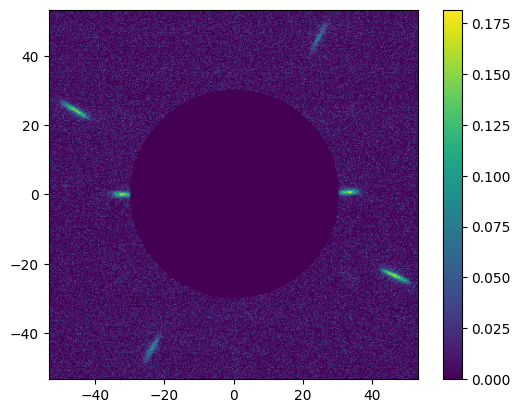

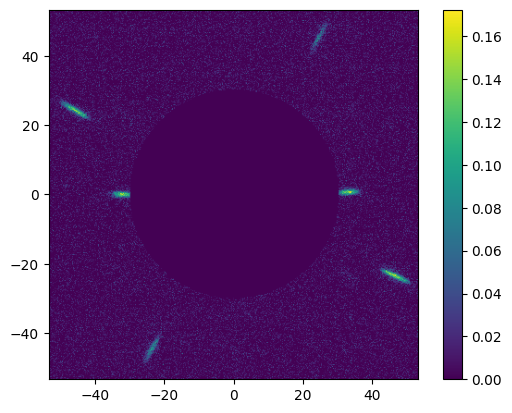

In [5]:
#function to get rid of background by thresholding
#img = ADC.filter_image(ADC.crop_image(fieldcube[0]))
img = ADC.crop_image(fieldcube[0])
img[img < 0] = 0
bgd_avg = np.mean(img.shaped[20:40,20:40])
img_subtracted = img - bgd_avg
img_subtracted[img_subtracted < 0 ] = 0

imshow_field(img)
plt.colorbar()
plt.figure()
imshow_field(img_subtracted)
plt.colorbar()
print(bgd_avg)

In [11]:
disps = np.zeros(len(fieldcube))
commands = []
speckle_angles = []
pointings = []


for i, field in enumerate(fieldcube):
    field_T = Field(field.shaped.T.ravel(),field.grid)
    filtered = ADC.filter_image(ADC.crop_image(field_T))
    ADC.set_psf(filtered)
    angles = ADC.find_speckle_angles2()
    pairs = ADC.speckle_pairs(angles)
    speckle_angles.append(angles)
    pointings.append(pairs)
    #commands.append(ADC.calculate_command(pairs))

pointings = np.array(pointings)
speckle_angles = np.array(speckle_angles)
#commands = np.array(commands)

In [12]:
print(speckle_angles.shape)
print(speckle_angles)

angle_avgs = np.mean(speckle_angles,axis=0)
print(angle_avgs)

(428, 4)
[[154.55307462 -25.4897855  150.72711488 -30.8203972 ]
 [156.17018488 -28.00484537 150.98978285 -32.69811707]
 [154.52859619 -24.68036594 150.01157735 -31.62099449]
 ...
 [156.40472631 -27.77404688 150.54159531 -26.90746469]
 [156.01638862 -25.56680695 149.62035456 -30.83440172]
 [155.98893138 -24.21013514 151.63274444 -32.26522649]]
[155.41489454 -26.54030471 150.02434224 -27.83466173]


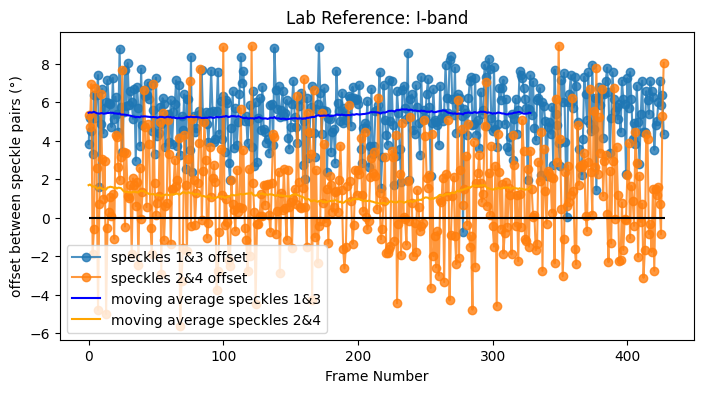

In [13]:
avg1 = moving_average((pointings[:,0]),n=100)
avg2 = moving_average((pointings[:,1]),n=100)

plt.figure(figsize=(18,4))
plt.subplot(1,2,1)
plt.plot((pointings[:,0]),'-o',label='speckles 1&3 offset',alpha=0.8)
plt.plot((pointings[:,1]),'-o',label='speckles 2&4 offset',alpha=0.8)
plt.plot(avg1,'-',label='moving average speckles 1&3',color='blue')
plt.plot(avg2,'-',label='moving average speckles 2&4',color='orange')
plt.hlines(0,0,len(pointings[:,0]),'black')
plt.xlabel('Frame Number')
plt.ylabel('offset between speckle pairs (°)')
plt.title('Lab Reference: I-band')
plt.legend()

In [14]:
point13 = pointings[:,0]
point24 = pointings[:,1]

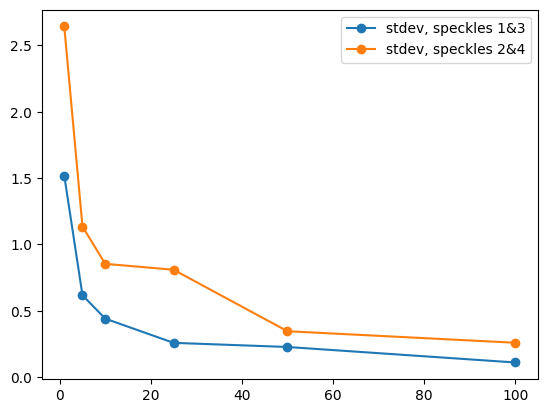

[1.5188297  0.61702556 0.44103514 0.25872913 0.22753039 0.11078332]
[2.64239992 1.13476237 0.85395973 0.80948106 0.3462992  0.25947179]


In [15]:
#looking at how averaging changes the variance
averages = np.array([1,5,10,25,50,100])
stds13 = np.zeros(len(averages))
stds24 = np.zeros(len(averages))

for i, average in enumerate(averages):
    means13 = block_means(point13, average)
    means24 = block_means(point24, average)
    stds13[i] = np.std(means13)
    stds24[i] = np.std(means24)

plt.plot(averages,stds13,'o-',label="stdev, speckles 1&3")
plt.plot(averages,stds24,'o-',label="stdev, speckles 2&4")
plt.legend()
plt.show()

print(stds13)
print(stds24)

In [16]:
#write the speckle pair angles to .csv so you can just reference them in the future
np.savetxt('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/pointings/speckles13_T/1sat.csv',point13,delimiter=',')
np.savetxt('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/pointings/speckles24_T/1sat.csv',point24,delimiter=',')

In [17]:
#my_data = np.genfromtxt('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/pointings/speckles13/05sat.csv',delimiter=',')